In [ ]:
# STEP 1: LOAD DATASET AND PERFORM INITIAL ANALYSIS

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

OUTPUT_DIR = Path("outputs_unsupervised_clustering")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

possible_paths = [
    Path("fast_food_cheat_meal_workout_burn(1).csv"),
    Path("/content/fast_food_cheat_meal_workout_burn(1).csv"),
    Path("fast_food_cheat_meal_workout_burn.csv"),
    Path("/content/fast_food_cheat_meal_workout_burn.csv")
]

DATA_PATH = next(
    (p for p in possible_paths if p.exists()),
    None
)

if DATA_PATH is None:
    try:
        from google.colab import files
        uploaded = files.upload()

        csv_files = [
            name for name in uploaded
            if name.lower().endswith(".csv")
        ]

        if not csv_files:
            raise ValueError("Please upload a CSV dataset.")

        DATA_PATH = Path(csv_files[0])

    except ImportError:
        raise FileNotFoundError(
            "Place your CSV in the notebook directory "
            "and update DATA_PATH."
        )

df = pd.read_csv(DATA_PATH)

print("DATASET OVERVIEW")
print("File:", DATA_PATH)
print("Shape:", df.shape)

print("\nFirst five records:")
print(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
print(df.describe(include="all").T)

Saving fast_food_cheat_meal_workout_burn.csv to fast_food_cheat_meal_workout_burn.csv
DATASET OVERVIEW
File: fast_food_cheat_meal_workout_burn.csv
Shape: (8000, 23)

First five records:
    order_id fast_food_chain                   meal_category  item_count  \
0  FFC-00001      McDonald's     Late-Night Value Menu Binge           3   
1  FFC-00002       Taco Bell     Fried Chicken Bucket & Slaw           5   
2  FFC-00003  Domino's Pizza      Pizza Feast & Cheesy Bread           2   
3  FFC-00004      McDonald's  Dessert Overload & Large Shake           2   
4  FFC-00005       Taco Bell       Double Burger & Large Fry           4   

   total_calories  fat_grams  saturated_fat_grams  carb_grams  sugar_grams  \
0            1015         47                   19         117           55   
1            1849        103                   32         166           61   
2            1920        106                   50         184           61   
3            1255         67                 

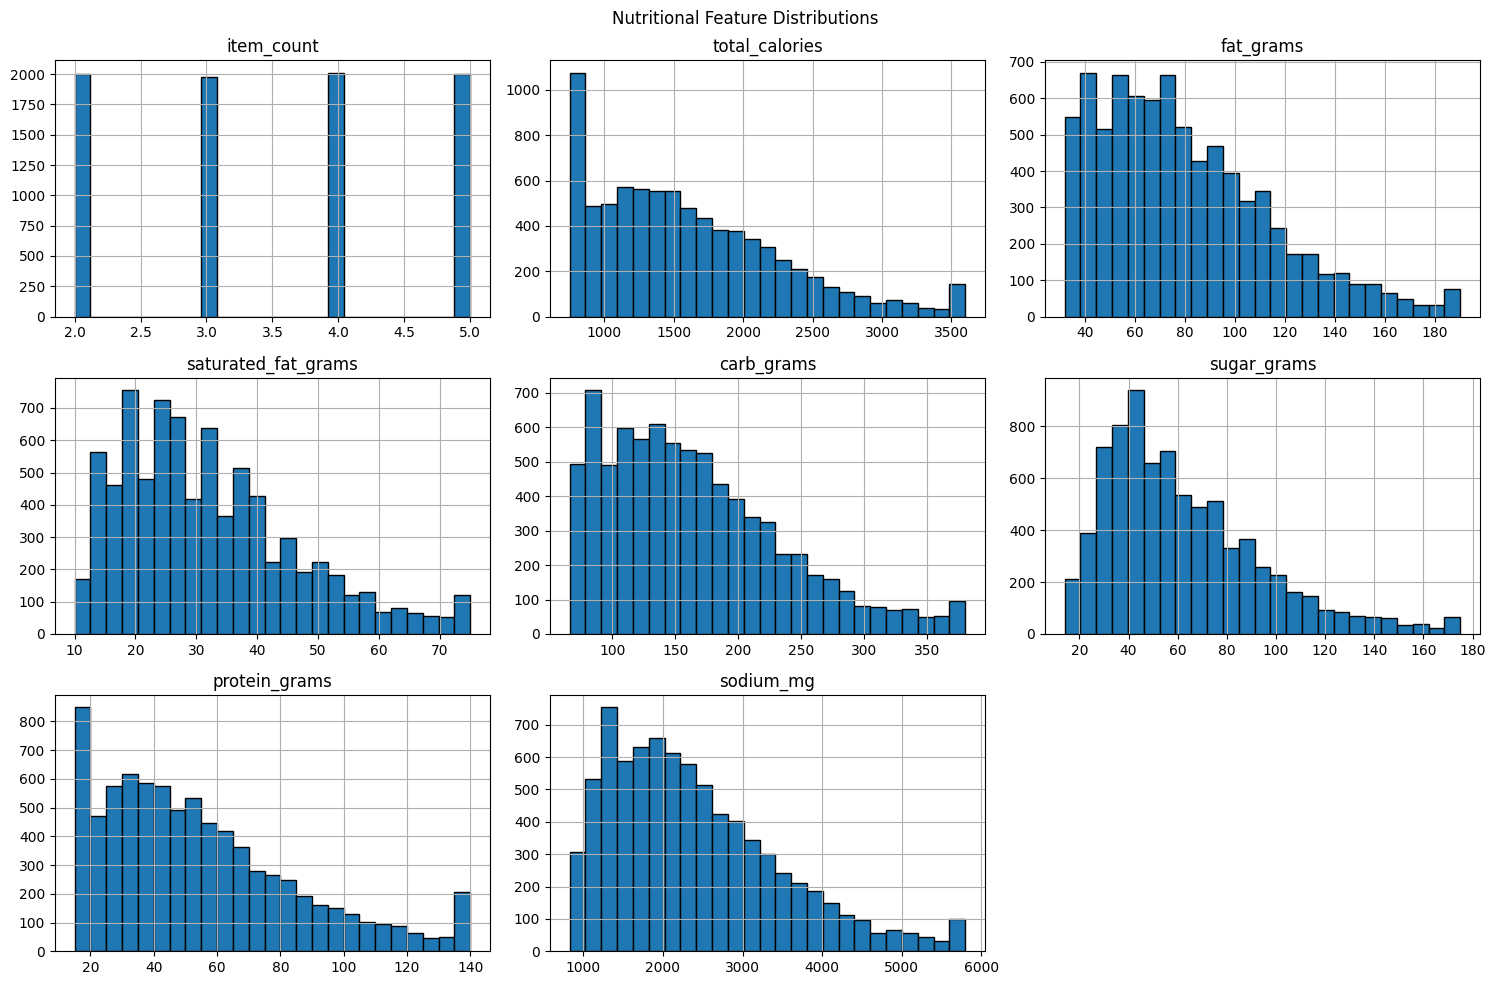

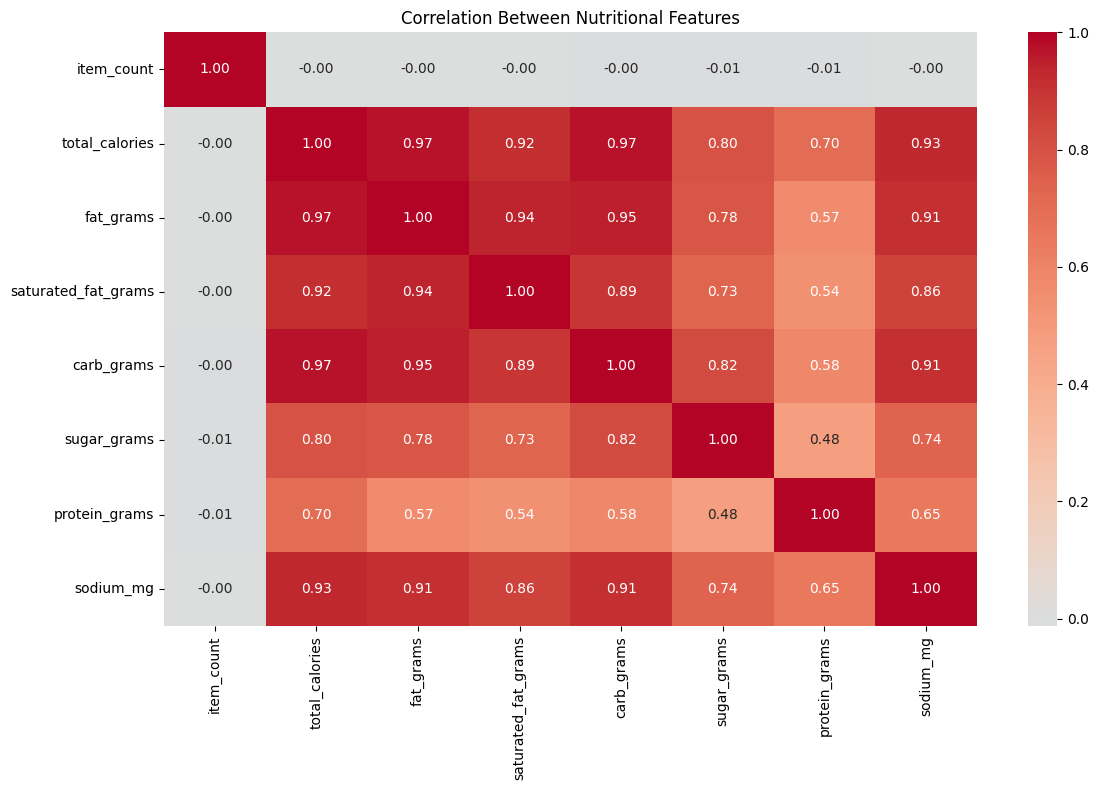

In [ ]:
# STEP 2: EXPLORATORY DATA ANALYSIS

numeric_features_eda = [
    "item_count",
    "total_calories",
    "fat_grams",
    "saturated_fat_grams",
    "carb_grams",
    "sugar_grams",
    "protein_grams",
    "sodium_mg"
]

available_numeric = [
    col for col in numeric_features_eda
    if col in df.columns
]

# Numerical feature distributions
df[available_numeric].hist(
    figsize=(15, 10),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Nutritional Feature Distributions")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "feature_distributions.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    df[available_numeric].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Nutritional Features")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "correlation_heatmap.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [ ]:
# STEP 3: SELECT FEATURES AND PREPROCESS DATA

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

TARGET = "workout_shock_tier"

CLUSTER_FEATURES = [
    "fast_food_chain",
    "meal_category",
    "item_count",
    "total_calories",
    "fat_grams",
    "saturated_fat_grams",
    "carb_grams",
    "sugar_grams",
    "protein_grams",
    "sodium_mg"
]

missing_columns = [
    c for c in CLUSTER_FEATURES
    if c not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Keep the original data for later cluster interpretation.
cluster_results = df.reset_index(drop=True).copy()

# Only these ten meal-related features enter the algorithms.
X_raw = cluster_results[CLUSTER_FEATURES].copy()

# Identify feature types.
numeric_features = X_raw.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_raw.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical preprocessing.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical encoding; compatible with multiple sklearn versions.
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

transformers = []

if numeric_features:
    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

# Fit the preprocessing pipeline and transform the data.
X_cluster = np.asarray(
    preprocessor.fit_transform(X_raw)
)

print("Preprocessing completed!")
print("Original features:", X_raw.shape[1])
print("Processed feature matrix:", X_cluster.shape)
print("Records available:", X_cluster.shape[0])
print("Features used:", CLUSTER_FEATURES)

Preprocessing completed!
Original features: 10
Processed feature matrix: (8000, 23)
Records available: 8000
Features used: ['fast_food_chain', 'meal_category', 'item_count', 'total_calories', 'fat_grams', 'saturated_fat_grams', 'carb_grams', 'sugar_grams', 'protein_grams', 'sodium_mg']


 K    Inertia  Silhouette Score
 2 45960.6757            0.3467
 3 38230.5466            0.2321
 4 34932.3113            0.1653
 5 32353.1577            0.1413
 6 30367.3308            0.1409
 7 29026.8051            0.1398
 8 28103.0923            0.1307
 9 27168.5538            0.1249
10 26617.2743            0.1159


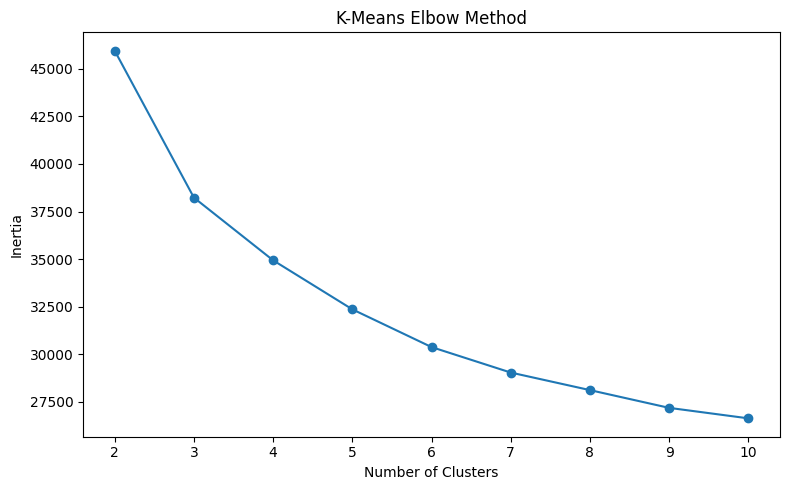

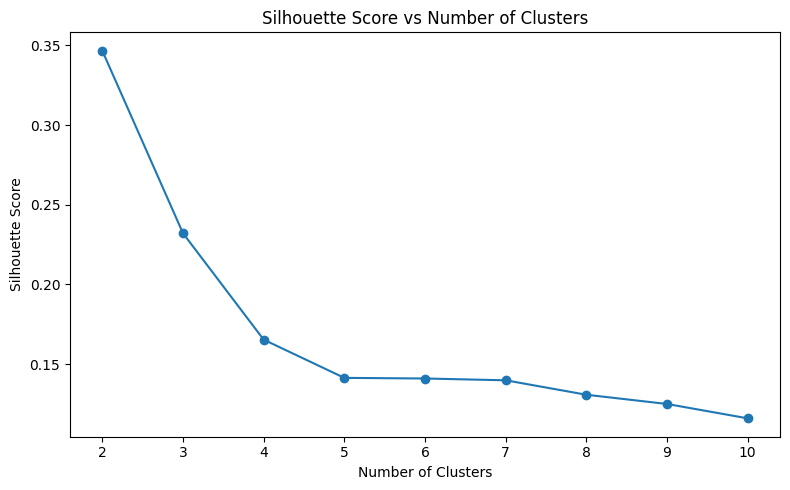

Best candidate K: 2


In [ ]:
# STEP 4: K-MEANS ELBOW METHOD AND SILHOUETTE SCORE

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

n_samples = len(X_cluster)

if n_samples < 3:
    raise ValueError("At least three records are needed.")

k_values = range(2, min(11, n_samples))

k_results = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_cluster)

    score = silhouette_score(
        X_cluster,
        labels,
        sample_size=min(2000, n_samples),
        random_state=42
    )

    k_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette Score": score
    })

k_results_df = pd.DataFrame(k_results)

print(k_results_df.round(4).to_string(index=False))

# Elbow plot
plt.figure(figsize=(8, 5))

plt.plot(
    k_results_df["K"],
    k_results_df["Inertia"],
    marker="o"
)

plt.title("K-Means Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "elbow_method.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Silhouette plot
plt.figure(figsize=(8, 5))

plt.plot(
    k_results_df["K"],
    k_results_df["Silhouette Score"],
    marker="o"
)

plt.title("Silhouette Score vs Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "silhouette_by_k.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Choose K with the highest tested Silhouette Score.
best_k = int(
    k_results_df.loc[
        k_results_df["Silhouette Score"].idxmax(),
        "K"
    ]
)

print("Best candidate K:", best_k)

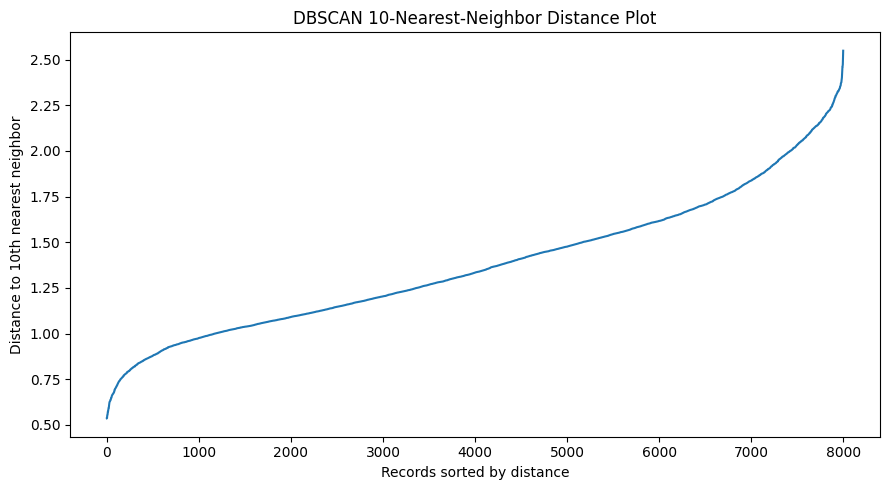


Training K-Means...
Clusters found: 2
Silhouette Score: 0.3466703546536218

Training Hierarchical Clustering...
Clusters found: 2
Silhouette Score: 0.291341776835338

Training Birch...
Clusters found: 2
Silhouette Score: 0.31966019069704005

Training Gaussian Mixture...
Clusters found: 2
Silhouette Score: 0.30869675722479306

Training DBSCAN...
Clusters found: 1
Silhouette Score: nan

========== CLUSTERING MODEL COMPARISON ==========
              Algorithm  Clusters Found  Noise Percentage  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Score
                K-Means               2               0.0            0.3467                1.1524                5502.4380
                  Birch               2               0.0            0.3197                1.2251                4750.2977
       Gaussian Mixture               2               0.0            0.3087                1.2088                5112.4400
Hierarchical Clustering               2               0.0            

In [ ]:
# STEP 5: TRAIN AND COMPARE CLUSTERING ALGORITHMS

from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering,
    Birch,
    DBSCAN
)

from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Inspect the 10-nearest-neighbor distances to help choose DBSCAN eps.
neighbors = NearestNeighbors(
    n_neighbors=10
)

neighbors.fit(X_cluster)

distances, _ = neighbors.kneighbors(X_cluster)

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))

plt.plot(k_distances)

plt.title("DBSCAN 10-Nearest-Neighbor Distance Plot")
plt.xlabel("Records sorted by distance")
plt.ylabel("Distance to 10th nearest neighbor")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "dbscan_neighbor_distances.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Adjust eps after inspecting the previous plot, if needed.
DBSCAN_EPS = 3.0
DBSCAN_MIN_SAMPLES = 10

models = {
    "K-Means": KMeans(
        n_clusters=best_k,
        random_state=42,
        n_init=10
    ),

    "Hierarchical Clustering": AgglomerativeClustering(
        n_clusters=best_k,
        linkage="ward"
    ),

    "Birch": Birch(
        n_clusters=best_k
    ),

    "Gaussian Mixture": GaussianMixture(
        n_components=best_k,
        covariance_type="diag",
        random_state=42,
        n_init=3
    ),

    "DBSCAN": DBSCAN(
        eps=DBSCAN_EPS,
        min_samples=DBSCAN_MIN_SAMPLES,
        n_jobs=-1
    )
}

trained_models = {}
labels_by_model = {}
evaluation_results = []


def evaluate_clusters(X, labels, remove_noise=False):
    """
    Evaluate valid clustering results.
    For DBSCAN, noise points (-1) are excluded from
    the internal quality metrics.
    """

    labels = np.asarray(labels)

    if remove_noise:
        mask = labels != -1
        X_eval = X[mask]
        y_eval = labels[mask]
    else:
        X_eval = X
        y_eval = labels

    unique_labels = np.unique(y_eval)
    number_of_clusters = len(unique_labels)

    metrics = {
        "Silhouette Score": np.nan,
        "Davies-Bouldin Index": np.nan,
        "Calinski-Harabasz Score": np.nan
    }

    if (
        number_of_clusters >= 2
        and number_of_clusters < len(y_eval)
    ):
        try:
            metrics["Silhouette Score"] = silhouette_score(
                X_eval,
                y_eval,
                sample_size=min(2000, len(y_eval)),
                random_state=42
            )

            metrics["Davies-Bouldin Index"] = (
                davies_bouldin_score(X_eval, y_eval)
            )

            metrics["Calinski-Harabasz Score"] = (
                calinski_harabasz_score(X_eval, y_eval)
            )

        except Exception as error:
            print("Metric calculation warning:", error)

    return metrics, number_of_clusters


for name, model in models.items():
    print(f"\nTraining {name}...")

    try:
        labels = model.fit_predict(X_cluster)

        labels_by_model[name] = labels
        trained_models[name] = model

        is_dbscan = name == "DBSCAN"

        metrics, number_of_clusters = evaluate_clusters(
            X_cluster,
            labels,
            remove_noise=is_dbscan
        )

        noise_percentage = (
            np.mean(labels == -1) * 100
            if is_dbscan else 0.0
        )

        evaluation_results.append({
            "Algorithm": name,
            "Clusters Found": number_of_clusters,
            "Noise Percentage": noise_percentage,
            **metrics
        })

        print("Clusters found:", number_of_clusters)
        print(
            "Silhouette Score:",
            metrics["Silhouette Score"]
        )

    except Exception as error:
        print(f"{name} failed: {error}")


results_df = pd.DataFrame(evaluation_results)

results_df = results_df.sort_values(
    "Silhouette Score",
    ascending=False,
    na_position="last"
).reset_index(drop=True)

print("\n========== CLUSTERING MODEL COMPARISON ==========")
print(results_df.round(4).to_string(index=False))

results_df.to_csv(
    OUTPUT_DIR / "clustering_model_comparison.csv",
    index=False
)

========== NUTRITIONAL CLUSTER PROFILES ==========
         Record Count  item_count  total_calories  fat_grams  saturated_fat_grams  carb_grams  sugar_grams  protein_grams  sodium_mg
Cluster                                                                                                                             
0                5275         3.5         1207.72      60.37                24.01      125.21        46.56          41.29    1799.86
1                2725         3.5         2366.93     118.17                47.43      244.84        92.63          78.72    3560.39

========== COMMON MEAL TYPES BY CLUSTER ==========
        fast_food_chain                  meal_category
Cluster                                               
0            McDonald's  Loaded Burrito, Nachos & Soda
1            McDonald's  Loaded Burrito, Nachos & Soda


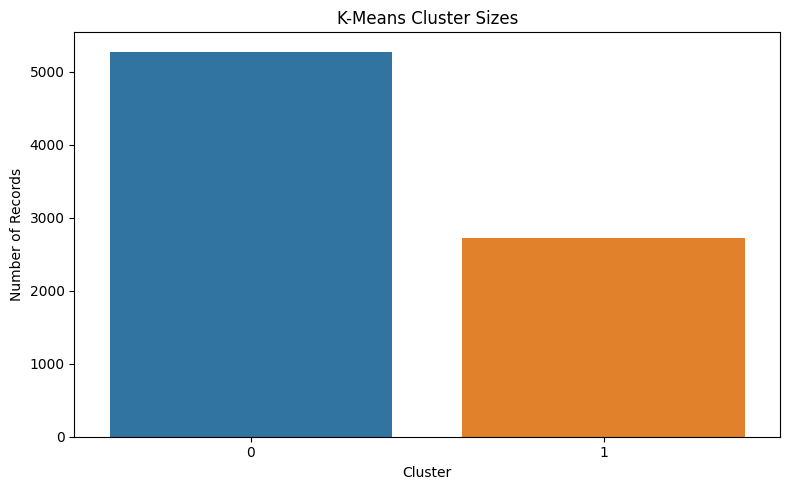


========== OPTIONAL POST-HOC LABEL COMPARISON ==========
workout_shock_tier  Extreme / Half-Marathon Toll  High Sweat Penalty  \
Cluster                                                                
0                                          0.157               0.402   
1                                          0.892               0.001   

workout_shock_tier  Moderate Burn  Severe Cardio Deficit  
Cluster                                                   
0                           0.036                  0.405  
1                           0.000                  0.107  


In [ ]:
# STEP 6: CLUSTER PROFILES AND INTERPRETATION

# Add cluster assignments for every successfully trained algorithm.
for name, labels in labels_by_model.items():
    safe_name = (
        name.replace(" ", "_")
        .replace("-", "_")
    )

    cluster_results[f"{safe_name}_Cluster"] = labels

# Use K-Means for the primary meal profile.
cluster_results["Cluster"] = labels_by_model["K-Means"]

# Summarize numeric nutritional characteristics.
profile_features = [
    "item_count",
    "total_calories",
    "fat_grams",
    "saturated_fat_grams",
    "carb_grams",
    "sugar_grams",
    "protein_grams",
    "sodium_mg"
]

cluster_profile = (
    cluster_results
    .groupby("Cluster")[profile_features]
    .mean()
    .round(2)
)

cluster_profile.insert(
    0,
    "Record Count",
    cluster_results.groupby("Cluster").size()
)

print("========== NUTRITIONAL CLUSTER PROFILES ==========")
print(cluster_profile.to_string())

# Most common fast-food chain and meal category per cluster.
def most_common_value(series):
    modes = series.mode(dropna=True)
    return modes.iloc[0] if len(modes) else "Unknown"

categorical_profile = (
    cluster_results.groupby("Cluster")
    .agg({
        "fast_food_chain": most_common_value,
        "meal_category": most_common_value
    })
)

print("\n========== COMMON MEAL TYPES BY CLUSTER ==========")
print(categorical_profile.to_string())

# Plot cluster sizes.
plt.figure(figsize=(8, 5))

sns.countplot(
    data=cluster_results,
    x="Cluster",
    hue="Cluster",
    legend=False
)

plt.title("K-Means Cluster Sizes")
plt.xlabel("Cluster")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "cluster_sizes.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Optional: compare clusters with existing labels AFTER clustering.
# The target was never included in the input features.
if TARGET in cluster_results.columns:
    label_comparison = pd.crosstab(
        cluster_results["Cluster"],
        cluster_results[TARGET],
        normalize="index"
    ).round(3)

    print("\n========== OPTIONAL POST-HOC LABEL COMPARISON ==========")
    print(label_comparison)

    label_comparison.to_csv(
        OUTPUT_DIR / "cluster_vs_existing_label.csv"
    )

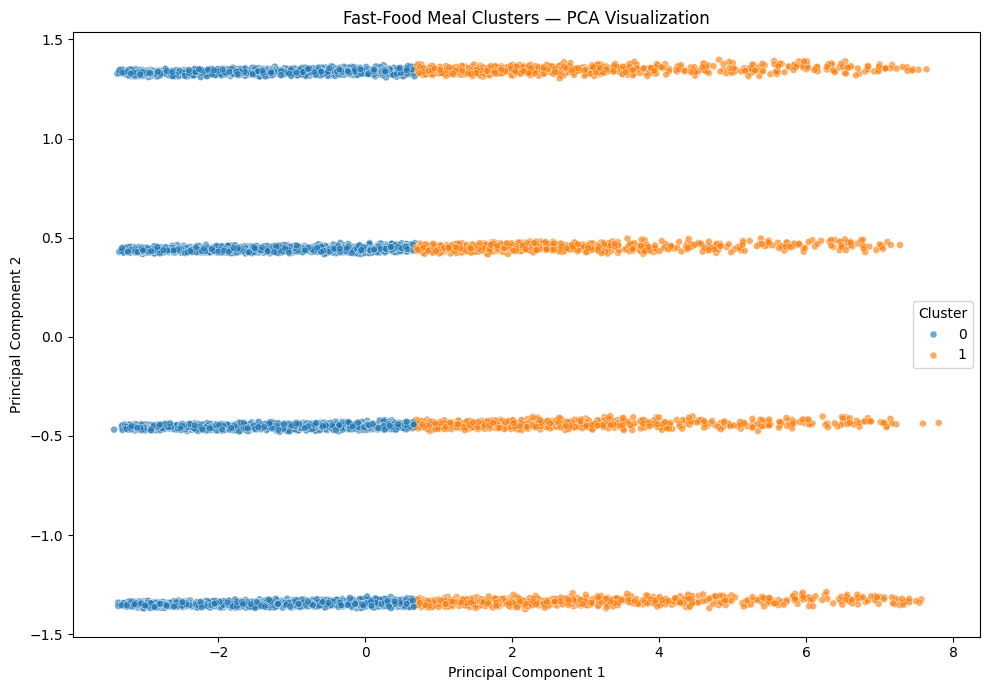

Variance explained by two PCA components: 70.31 %


In [ ]:
# STEP 7: PCA VISUALIZATION

from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_cluster)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": labels_by_model["K-Means"].astype(str)
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    alpha=0.65,
    s=25
)

plt.title("Fast-Food Meal Clusters — PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "pca_cluster_visualization.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print(
    "Variance explained by two PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [ ]:
# ============================================================
# STEP 8: SAVE CLUSTERING RESULTS AND MODELS
# ============================================================

import sys
import json
import joblib
import pandas as pd
from pathlib import Path

# Workaround for deeply nested Python objects during serialization
sys.setrecursionlimit(10000)

OUTPUT_DIR = Path("outputs_unsupervised_clustering")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. SAVE CLUSTER ASSIGNMENTS
# ------------------------------------------------------------

cluster_results.to_csv(
    OUTPUT_DIR / "cluster_assignments.csv",
    index=False
)

print("Cluster assignments saved.")

# ------------------------------------------------------------
# 2. SAVE EVALUATION RESULTS
# ------------------------------------------------------------

results_df.to_csv(
    OUTPUT_DIR / "clustering_model_comparison.csv",
    index=False
)

k_results_df.to_csv(
    OUTPUT_DIR / "kmeans_k_selection.csv",
    index=False
)

cluster_profile.to_csv(
    OUTPUT_DIR / "cluster_profiles.csv"
)

categorical_profile.to_csv(
    OUTPUT_DIR / "cluster_categories.csv"
)

print("Evaluation tables and cluster profiles saved.")

# ------------------------------------------------------------
# 3. SAVE PREPROCESSOR SEPARATELY
# ------------------------------------------------------------

try:
    joblib.dump(
        preprocessor,
        OUTPUT_DIR / "preprocessor.joblib",
        compress=3
    )

    print("Preprocessor saved successfully.")

except Exception as error:
    print("Preprocessor save failed:", repr(error))

# ------------------------------------------------------------
# 4. SAVE EACH CLUSTERING MODEL SEPARATELY
# ------------------------------------------------------------

for model_name, model in trained_models.items():

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    model_path = OUTPUT_DIR / f"{safe_name}_model.joblib"

    try:
        joblib.dump(
            model,
            model_path,
            compress=3
        )

        print(f"Saved: {model_path.name}")

    except Exception as error:
        print(f"Could not save {model_name}: {repr(error)}")

# ------------------------------------------------------------
# 5. SAVE MODEL CONFIGURATION
# ------------------------------------------------------------

metadata = {
    "selected_k": int(best_k),
    "input_features": list(CLUSTER_FEATURES),
    "algorithms": list(trained_models.keys()),
    "dbscan_eps": float(DBSCAN_EPS),
    "dbscan_min_samples": int(DBSCAN_MIN_SAMPLES)
}

with open(
    OUTPUT_DIR / "model_metadata.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(metadata, file, indent=4)

print("\n========== SAVING COMPLETED ==========")
print("Output directory:", OUTPUT_DIR.resolve())

print("\nGenerated files:")

for file_path in sorted(OUTPUT_DIR.iterdir()):
    if file_path.is_file():
        print(
            f"{file_path.name} — "
            f"{file_path.stat().st_size / 1024:.1f} KB"
        )

Cluster assignments saved.
Evaluation tables and cluster profiles saved.
Preprocessor saved successfully.
Saved: k_means_model.joblib
Saved: hierarchical_clustering_model.joblib
Saved: birch_model.joblib
Saved: gaussian_mixture_model.joblib
Saved: dbscan_model.joblib

========== SAVING COMPLETED ==========
Output directory: /content/outputs_unsupervised_clustering

Generated files:
birch_model.joblib — 1036.4 KB
cluster_assignments.csv — 1414.9 KB
cluster_categories.csv — 0.1 KB
cluster_profiles.csv — 0.2 KB
cluster_sizes.png — 38.6 KB
cluster_vs_existing_label.csv — 0.1 KB
clustering_model_comparison.csv — 0.4 KB
correlation_heatmap.png — 195.2 KB
dbscan_model.joblib — 339.5 KB
dbscan_neighbor_distances.png — 85.5 KB
elbow_method.png — 75.7 KB
fast_food_unsupervised_models.joblib — 3998.8 KB
feature_distributions.png — 223.8 KB
gaussian_mixture_model.joblib — 2.1 KB
hierarchical_clustering_model.joblib — 43.2 KB
k_means_model.joblib — 3.5 KB
kmeans_k_selection.csv — 0.4 KB
model_metad

In [ ]:
# STEP 10: DBSCAN HYPERPARAMETER TUNING

from sklearn.cluster import DBSCAN
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
import pandas as pd
import numpy as np

dbscan_results = []

# Try different neighborhood radii and minimum point counts
eps_values = [0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0]
min_samples_values = [5, 10, 15]

for eps in eps_values:
    for min_samples in min_samples_values:

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            n_jobs=-1
        )

        labels = model.fit_predict(X_cluster)

        # DBSCAN assigns -1 to noise points
        non_noise = labels != -1
        labels_valid = labels[non_noise]
        X_valid = X_cluster[non_noise]

        n_clusters = len(set(labels_valid))
        noise_pct = (1 - non_noise.mean()) * 100

        row = {
            "eps": eps,
            "min_samples": min_samples,
            "clusters": n_clusters,
            "noise_pct": noise_pct,
            "silhouette": np.nan,
            "davies_bouldin": np.nan,
            "calinski_harabasz": np.nan
        }

        # Evaluate only if at least two clusters remain
        if 2 <= n_clusters < len(labels_valid):

            row["silhouette"] = silhouette_score(
                X_valid,
                labels_valid,
                sample_size=min(2000, len(labels_valid)),
                random_state=42
            )

            row["davies_bouldin"] = davies_bouldin_score(
                X_valid,
                labels_valid
            )

            row["calinski_harabasz"] = calinski_harabasz_score(
                X_valid,
                labels_valid
            )

        dbscan_results.append(row)

dbscan_tuning_df = pd.DataFrame(dbscan_results)

valid_dbscan = dbscan_tuning_df.dropna(
    subset=["silhouette"]
)

print("========== DBSCAN TUNING RESULTS ==========")

print(
    dbscan_tuning_df.sort_values(
        "silhouette",
        ascending=False,
        na_position="last"
    ).round(4).to_string(index=False)
)

if not valid_dbscan.empty:
    best_dbscan = valid_dbscan.loc[
        valid_dbscan["silhouette"].idxmax()
    ]

    print("\nBest valid DBSCAN configuration:")
    print(best_dbscan.to_string())

    tuned_dbscan = DBSCAN(
        eps=float(best_dbscan["eps"]),
        min_samples=int(best_dbscan["min_samples"]),
        n_jobs=-1
    )

    tuned_labels = tuned_dbscan.fit_predict(X_cluster)

    cluster_results["DBSCAN_Tuned_Cluster"] = tuned_labels

    dbscan_tuning_df.to_csv(
        OUTPUT_DIR / "dbscan_tuning_results.csv",
        index=False
    )

    print("\nTuned DBSCAN results saved.")
else:
    print(
        "\nNo tested setting formed multiple non-noise clusters. "
        "Consider adjusting the feature representation or "
        "testing a different clustering method."
    )

========== DBSCAN TUNING RESULTS ==========
 eps  min_samples  clusters  noise_pct  silhouette  davies_bouldin  calinski_harabasz
0.75           15         3    99.4000      0.6035          0.6142           117.0110
0.50            5        45    96.1750      0.5742          0.6121           119.2935
0.75           10        36    94.0000      0.4443          0.9136           111.5512
1.75            5        13     5.2625      0.3428          1.2272            37.0164
0.75            5       190    75.6750      0.3163          1.0708            68.2828
1.00           15        32    85.7750      0.1985          1.2952            64.2025
1.50           15         3    27.4750      0.1255          1.1447            18.3778
1.50            5        13    14.4375      0.0989          0.9503            17.6485
1.00           10        60    70.4500      0.0736          1.4445            51.7369
1.25           15        50    51.5125      0.0417          1.9125            62.0905
1.25      

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# ============================================================
# STEP 11: FINAL COMPARISON INCLUDING TUNED DBSCAN
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

OUTPUT_DIR = Path("outputs_unsupervised_clustering")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Start with the original comparison
final_results = results_df.copy()

# Add tuned DBSCAN if a valid configuration was found
if (
    "dbscan_tuning_df" in globals()
    and not dbscan_tuning_df.empty
):

    valid_dbscan = dbscan_tuning_df.dropna(
        subset=["silhouette"]
    )

    if not valid_dbscan.empty:

        best_dbscan = valid_dbscan.loc[
            valid_dbscan["silhouette"].idxmax()
        ]

        tuned_row = {
            "Algorithm": "DBSCAN (Tuned)",
            "Clusters Found": int(best_dbscan["clusters"]),
            "Noise Percentage": float(best_dbscan["noise_pct"]),
            "Silhouette Score": float(best_dbscan["silhouette"]),
            "Davies-Bouldin Index": float(
                best_dbscan["davies_bouldin"]
            ),
            "Calinski-Harabasz Score": float(
                best_dbscan["calinski_harabasz"]
            )
        }

        final_results = pd.concat(
            [
                final_results[
                    final_results["Algorithm"] != "DBSCAN"
                ],
                pd.DataFrame([tuned_row])
            ],
            ignore_index=True
        )

        print("Best tuned DBSCAN configuration:")
        print("eps:", best_dbscan["eps"])
        print("min_samples:", best_dbscan["min_samples"])

    else:
        print(
            "No DBSCAN configuration produced a valid "
            "Silhouette Score. Keeping the original results."
        )

# Sort by Silhouette Score
final_results = final_results.sort_values(
    "Silhouette Score",
    ascending=False,
    na_position="last"
).reset_index(drop=True)

print("\n========== FINAL MODEL COMPARISON ==========")
print(final_results.round(4).to_string(index=False))

# Save the comparison
final_results.to_csv(
    OUTPUT_DIR / "final_algorithm_comparison.csv",
    index=False
)

print("\nFinal comparison saved successfully!")

# Display the highest-scoring valid candidate
valid_results = final_results.dropna(
    subset=["Silhouette Score"]
)

if not valid_results.empty:
    winner = valid_results.iloc[0]

    print("\nBest candidate by Silhouette Score:")
    print("Algorithm:", winner["Algorithm"])
    print("Clusters:", int(winner["Clusters Found"]))
    print(
        "Silhouette Score:",
        round(winner["Silhouette Score"], 4)
    )

Best tuned DBSCAN configuration:
eps: 0.75
min_samples: 15.0

========== FINAL MODEL COMPARISON ==========
              Algorithm  Clusters Found  Noise Percentage  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Score
         DBSCAN (Tuned)               3              99.4            0.6035                0.6142                 117.0110
                K-Means               2               0.0            0.3467                1.1524                5502.4380
                  Birch               2               0.0            0.3197                1.2251                4750.2977
       Gaussian Mixture               2               0.0            0.3087                1.2088                5112.4400
Hierarchical Clustering               2               0.0            0.2913                1.2587                4717.5094

Final comparison saved successfully!

Best candidate by Silhouette Score:
Algorithm: DBSCAN (Tuned)
Clusters: 3
Silhouette Score: 0.6035



Selected DBSCAN parameters:
eps: 1.75
min_samples: 5.0

========== THREE-ALGORITHM COMPARISON ==========
              Algorithm  Clusters Found  Noise Percentage  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Score
                K-Means               2            0.0000            0.3467                1.1524                5502.4380
                 DBSCAN              13            5.2625            0.3428                1.2272                  37.0164
Hierarchical Clustering               2            0.0000            0.2913                1.2587                4717.5094


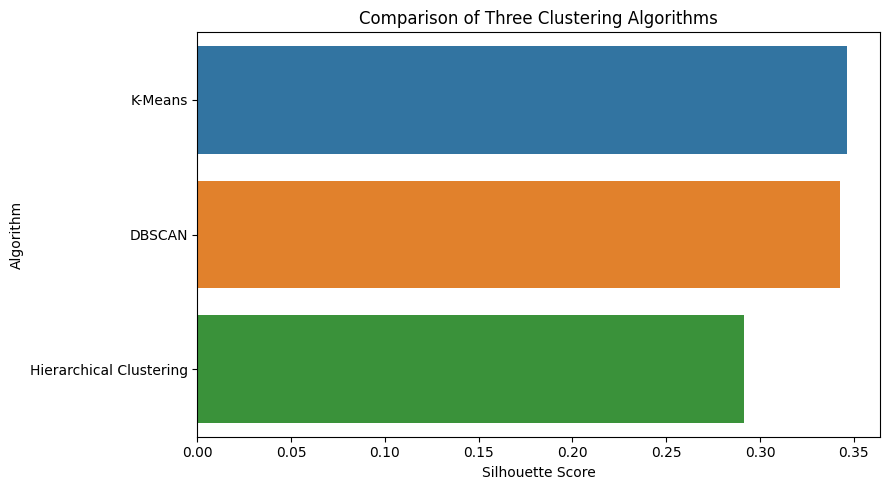


========== COMPLETED ==========
Algorithms retained: ['K-Means', 'Hierarchical Clustering', 'DBSCAN']
Model comparison saved.
Cluster assignments saved.
Models saved separately.
Output folder: /content/outputs_unsupervised_clustering


In [ ]:
# ============================================================
# UNSUPERVISED LEARNING: THREE ALGORITHMS ONLY
# K-Means, Hierarchical Clustering, DBSCAN
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

OUTPUT_DIR = Path("outputs_unsupervised_clustering")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. HELPER FUNCTION FOR CLUSTER EVALUATION
# ------------------------------------------------------------

def evaluate_clustering(X, labels, exclude_noise=False):

    labels = np.asarray(labels)

    if exclude_noise:
        mask = labels != -1
        X_eval = X[mask]
        labels_eval = labels[mask]
    else:
        X_eval = X
        labels_eval = labels

    unique_clusters = np.unique(labels_eval)
    n_clusters = len(unique_clusters)

    metrics = {
        "Silhouette Score": np.nan,
        "Davies-Bouldin Index": np.nan,
        "Calinski-Harabasz Score": np.nan
    }

    if 2 <= n_clusters < len(labels_eval):

        metrics["Silhouette Score"] = silhouette_score(
            X_eval,
            labels_eval,
            sample_size=min(2000, len(labels_eval)),
            random_state=42
        )

        metrics["Davies-Bouldin Index"] = (
            davies_bouldin_score(X_eval, labels_eval)
        )

        metrics["Calinski-Harabasz Score"] = (
            calinski_harabasz_score(X_eval, labels_eval)
        )

    return metrics, n_clusters


# ------------------------------------------------------------
# 2. TRAIN K-MEANS
# ------------------------------------------------------------

kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_cluster)


# ------------------------------------------------------------
# 3. TRAIN HIERARCHICAL CLUSTERING
# ------------------------------------------------------------

hierarchical_model = AgglomerativeClustering(
    n_clusters=best_k,
    linkage="ward"
)

hierarchical_labels = hierarchical_model.fit_predict(X_cluster)


# ------------------------------------------------------------
# 4. TUNE DBSCAN
# ------------------------------------------------------------

dbscan_rows = []

eps_values = [
    0.5, 0.75, 1.0, 1.25, 1.5,
    1.75, 2.0, 2.5, 3.0
]

min_samples_values = [5, 10, 15]

for eps in eps_values:
    for min_samples in min_samples_values:

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            n_jobs=-1
        )

        labels = model.fit_predict(X_cluster)

        noise_pct = np.mean(labels == -1) * 100

        metrics, n_clusters = evaluate_clustering(
            X_cluster,
            labels,
            exclude_noise=True
        )

        dbscan_rows.append({
            "eps": eps,
            "min_samples": min_samples,
            "Clusters Found": n_clusters,
            "Noise Percentage": noise_pct,
            **metrics
        })

dbscan_tuning_df = pd.DataFrame(dbscan_rows)

# Prefer a valid solution with at most 50% noise.
# If none exists, select the valid solution with the least noise.
valid_dbscan = dbscan_tuning_df[
    (dbscan_tuning_df["Clusters Found"] >= 2)
    & dbscan_tuning_df["Silhouette Score"].notna()
].copy()

acceptable_dbscan = valid_dbscan[
    valid_dbscan["Noise Percentage"] <= 50
]

if not acceptable_dbscan.empty:

    selected_dbscan = acceptable_dbscan.sort_values(
        "Silhouette Score",
        ascending=False
    ).iloc[0]

elif not valid_dbscan.empty:

    selected_dbscan = valid_dbscan.sort_values(
        ["Noise Percentage", "Silhouette Score"],
        ascending=[True, False]
    ).iloc[0]

    print(
        "Warning: no tested DBSCAN configuration assigned "
        "at least half of the records to clusters."
    )

else:
    selected_dbscan = None
    print(
        "Warning: DBSCAN did not find a valid multi-cluster "
        "solution with the tested parameters."
    )

if selected_dbscan is not None:

    dbscan_model = DBSCAN(
        eps=float(selected_dbscan["eps"]),
        min_samples=int(selected_dbscan["min_samples"]),
        n_jobs=-1
    )

    dbscan_labels = dbscan_model.fit_predict(X_cluster)

    print("\nSelected DBSCAN parameters:")
    print("eps:", selected_dbscan["eps"])
    print("min_samples:", selected_dbscan["min_samples"])

else:
    # Retain DBSCAN in the comparison, but report if it fails.
    dbscan_model = DBSCAN(
        eps=0.75,
        min_samples=15,
        n_jobs=-1
    )

    dbscan_labels = dbscan_model.fit_predict(X_cluster)


# ------------------------------------------------------------
# 5. STORE ONLY THREE ALGORITHMS
# ------------------------------------------------------------

trained_models = {
    "K-Means": kmeans_model,
    "Hierarchical Clustering": hierarchical_model,
    "DBSCAN": dbscan_model
}

labels_by_model = {
    "K-Means": kmeans_labels,
    "Hierarchical Clustering": hierarchical_labels,
    "DBSCAN": dbscan_labels
}


# ------------------------------------------------------------
# 6. COMPARE THREE ALGORITHMS
# ------------------------------------------------------------

evaluation_rows = []

for name, labels in labels_by_model.items():

    is_dbscan = name == "DBSCAN"

    metrics, n_clusters = evaluate_clustering(
        X_cluster,
        labels,
        exclude_noise=is_dbscan
    )

    noise_percentage = (
        np.mean(labels == -1) * 100
        if is_dbscan else 0.0
    )

    evaluation_rows.append({
        "Algorithm": name,
        "Clusters Found": n_clusters,
        "Noise Percentage": noise_percentage,
        **metrics
    })

results_df = pd.DataFrame(evaluation_rows)

results_df = results_df.sort_values(
    "Silhouette Score",
    ascending=False,
    na_position="last"
).reset_index(drop=True)

print("\n========== THREE-ALGORITHM COMPARISON ==========")
print(results_df.round(4).to_string(index=False))


# ------------------------------------------------------------
# 7. SAVE COMPARISON AND DBSCAN TUNING RESULTS
# ------------------------------------------------------------

results_df.to_csv(
    OUTPUT_DIR / "clustering_model_comparison.csv",
    index=False
)

dbscan_tuning_df.to_csv(
    OUTPUT_DIR / "dbscan_tuning_results.csv",
    index=False
)


# ------------------------------------------------------------
# 8. VISUALIZE SILHOUETTE SCORES
# ------------------------------------------------------------

plot_data = results_df.dropna(
    subset=["Silhouette Score"]
)

plt.figure(figsize=(9, 5))

if not plot_data.empty:

    sns.barplot(
        data=plot_data,
        x="Silhouette Score",
        y="Algorithm",
        hue="Algorithm",
        legend=False
    )

    plt.title("Comparison of Three Clustering Algorithms")
    plt.xlabel("Silhouette Score")
    plt.ylabel("Algorithm")
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "three_algorithm_comparison.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("No valid Silhouette Scores to visualize.")


# ------------------------------------------------------------
# 9. UPDATE CLUSTER ASSIGNMENTS
# ------------------------------------------------------------

# Remove stale columns generated by the previous four/five-model run.
old_columns = [
    "Cluster",
    "K-Means_Cluster",
    "K_Means_Cluster",
    "Hierarchical_Clustering_Cluster",
    "DBSCAN_Cluster",
    "DBSCAN_Tuned_Cluster",
    "Birch_Cluster",
    "Gaussian_Mixture_Cluster"
]

cluster_results = cluster_results.drop(
    columns=old_columns,
    errors="ignore"
)

cluster_results["Cluster"] = kmeans_labels
cluster_results["K_Means_Cluster"] = kmeans_labels
cluster_results["Hierarchical_Clustering_Cluster"] = (
    hierarchical_labels
)
cluster_results["DBSCAN_Cluster"] = dbscan_labels

cluster_results.to_csv(
    OUTPUT_DIR / "cluster_assignments.csv",
    index=False
)


# ------------------------------------------------------------
# 10. SAVE MODELS SEPARATELY
# ------------------------------------------------------------

joblib.dump(
    preprocessor,
    OUTPUT_DIR / "preprocessor.joblib",
    compress=3
)

for name, model in trained_models.items():

    filename = (
        name.lower()
        .replace(" ", "_")
        .replace("-", "_")
        .replace("/", "_")
    )

    joblib.dump(
        model,
        OUTPUT_DIR / f"{filename}_model.joblib",
        compress=3
    )

print("\n========== COMPLETED ==========")
print("Algorithms retained:", list(trained_models.keys()))
print("Model comparison saved.")
print("Cluster assignments saved.")
print("Models saved separately.")
print("Output folder:", OUTPUT_DIR.resolve())

In [ ]:
# ============================================================
# STEP 12: FINAL REPORT FOR THREE CLUSTERING ALGORITHMS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

OUTPUT_DIR = Path("outputs_unsupervised_clustering")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Verify that only the three required algorithms are present
expected_algorithms = {
    "K-Means",
    "Hierarchical Clustering",
    "DBSCAN"
}

actual_algorithms = set(results_df["Algorithm"])

print("========== FINAL ALGORITHM COMPARISON ==========")
print(results_df.round(4).to_string(index=False))

if actual_algorithms != expected_algorithms:
    print("\nWarning: Check the algorithm names in results_df.")
    print("Expected:", expected_algorithms)
    print("Found:", actual_algorithms)
else:
    print("\nConfirmed: Exactly three algorithms are included.")

# 2. Generate nutritional profiles for K-Means clusters
cluster_results["Cluster"] = labels_by_model["K-Means"]

profile_features = [
    "item_count",
    "total_calories",
    "fat_grams",
    "saturated_fat_grams",
    "carb_grams",
    "sugar_grams",
    "protein_grams",
    "sodium_mg"
]

profile_features = [
    col for col in profile_features
    if col in cluster_results.columns
]

cluster_profile = (
    cluster_results.groupby("Cluster")[profile_features]
    .mean()
    .round(2)
)

cluster_profile.insert(
    0,
    "Record Count",
    cluster_results.groupby("Cluster").size()
)

print("\n========== K-MEANS CLUSTER PROFILES ==========")
print(cluster_profile.to_string())

# 3. Save final tables
results_df.to_csv(
    OUTPUT_DIR / "final_algorithm_comparison.csv",
    index=False
)

cluster_profile.to_csv(
    OUTPUT_DIR / "final_cluster_profiles.csv"
)

cluster_results.to_csv(
    OUTPUT_DIR / "final_cluster_assignments.csv",
    index=False
)

# 4. Create a report-ready summary
summary_lines = [
    "UNSUPERVISED MACHINE LEARNING PROJECT",
    "Fast Food Cheat Meal and Workout Burn Dataset",
    "",
    "Algorithms used:",
    "1. K-Means",
    "2. Hierarchical Clustering",
    "3. DBSCAN",
    "",
    "The target label was excluded from clustering inputs.",
    "Cluster quality was assessed with internal clustering metrics.",
    "",
    "ALGORITHM COMPARISON",
    results_df.round(4).to_string(index=False),
    "",
    "K-MEANS CLUSTER PROFILES",
    cluster_profile.to_string(),
    "",
    "INTERPRETATION",
    "K-Means and Hierarchical Clustering assign each record to a cluster.",
    "DBSCAN can label records as noise, depending on its parameters.",
    "A high Silhouette Score alone does not establish the best model.",
    "Consider cluster separation, the number of records assigned,",
    "noise percentage, and the usefulness of the cluster profiles."
]

(OUTPUT_DIR / "final_project_report.txt").write_text(
    "\n".join(summary_lines) + "\n",
    encoding="utf-8"
)

print("\n========== PROJECT COMPLETED ==========")
print("Final files saved to:", OUTPUT_DIR.resolve())
print("Comparison: final_algorithm_comparison.csv")
print("Profiles: final_cluster_profiles.csv")
print("Assignments: final_cluster_assignments.csv")
print("Report: final_project_report.txt")

========== FINAL ALGORITHM COMPARISON ==========
              Algorithm  Clusters Found  Noise Percentage  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Score
                K-Means               2            0.0000            0.3467                1.1524                5502.4380
                 DBSCAN              13            5.2625            0.3428                1.2272                  37.0164
Hierarchical Clustering               2            0.0000            0.2913                1.2587                4717.5094

Confirmed: Exactly three algorithms are included.

========== K-MEANS CLUSTER PROFILES ==========
         Record Count  item_count  total_calories  fat_grams  saturated_fat_grams  carb_grams  sugar_grams  protein_grams  sodium_mg
Cluster                                                                                                                             
0                5275         3.5         1207.72      60.37                24.01      125.21 